# 05 — External validation on NHANES
**Plan:** [`docs/external_validation_plan.md`](../docs/external_validation_plan.md), committed before any outcome was examined.
Section numbers below (§5.1 …) refer to that plan.

The saved models are applied **exactly as trained on Pima women**. Nothing is retrained, and the thresholds are the saved ones.
The only thing fitted here is the separate recalibration demo (§5.4).

**What's different about NHANES:** US women from 2005–2016, all ethnicities, not previously diagnosed, with a completed glucose tolerance test.
Family-history score and 2-hour insulin aren't available, so they are passed as missing and the models fill them in, just as the app does.

In [1]:
import sys, json
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.optimize import minimize_scalar
from scipy.special import expit, logit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split

from src.data import load_clean, train_test, PROJECT_ROOT
from src.models import GuidelineRule, sensitivity_at_rate
from src.nhanes import VALIDATION_CSV

sns.set_theme(style="whitegrid")
meta = json.loads((PROJECT_ROOT / "models" / "metadata.json").read_text())
models = {k: joblib.load(PROJECT_ROOT / v["file"]) for k, v in meta["models"].items()}
nh = pd.read_csv(VALIDATION_CSV, index_col=0)
y = nh["Outcome"].to_numpy()
pima_train, pima_test = train_test(load_clean())
N_BOOT, SEED = 5000, 42

print(f"NHANES women: {len(nh)}, undiagnosed diabetes: {y.sum()} ({y.mean():.1%})")
print(f"Pima (all):   {len(pima_train) + len(pima_test)}, diabetes rate {pd.concat([pima_train, pima_test])['Outcome'].mean():.1%}")

NHANES women: 5298, undiagnosed diabetes: 451 (8.5%)
Pima (all):   768, diabetes rate 34.9%


## 0. How different is this population?
A model can only transfer if the new patients look roughly like the old ones. We compare the inputs side by side.

In [2]:
cols = ["Age", "BMI", "BloodPressure", "Pregnancies", "SkinThickness", "Glucose"]
pima_all = pd.concat([pima_train, pima_test])
comp = pd.DataFrame({
    "Pima median": pima_all[cols].median(), "NHANES median": nh[cols].median(),
    "Pima % missing": pima_all[cols].isna().mean().mul(100).round(0),
    "NHANES % missing": nh[cols].isna().mean().mul(100).round(0),
}).round(1)
comp.loc["Outcome rate %"] = [round(pima_all.Outcome.mean() * 100, 1), round(y.mean() * 100, 1), np.nan, np.nan]
comp

,Pima median,NHANES median,Pima % missing,NHANES % missing
Age,29.0,47.0,0.0,0.0
BMI,32.3,27.7,1.0,1.0
BloodPressure,72.0,67.3,5.0,3.0
Pregnancies,3.0,3.0,0.0,7.0
SkinThickness,29.0,24.0,30.0,54.0
Glucose,117.0,110.0,1.0,0.0
Outcome rate %,34.9,8.5,NaN,NaN


In [3]:
def scores(df, pedigree=None):
    X = df.copy()
    if pedigree is not None:
        X["DiabetesPedigree"] = pedigree
    return {
        "rule": GuidelineRule().predict(X).astype(float),
        "no_lab": models["no_lab"].predict_proba(X[meta["models"]["no_lab"]["features"]])[:, 1],
        "full": models["full"].predict_proba(X[meta["models"]["full"]["features"]])[:, 1],
    }

S = scores(nh)
rule_rate = S["rule"].mean()
print(f"Guideline rule refers {rule_rate:.1%} of NHANES women (Pima test: 31.2%)")

Guideline rule refers 51.8% of NHANES women (Pima test: 31.2%)


## §5.1 Primary: no-lab model vs guideline rule at the rule's referral rate

In [4]:
def compare_at_rule_rate(y, s, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    point = sensitivity_at_rate(y, s["no_lab"], s["rule"].mean()) - sensitivity_at_rate(y, s["rule"], s["rule"].mean())
    diffs = []
    n = len(y)
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        rate = s["rule"][i].mean()
        diffs.append(sensitivity_at_rate(y[i], s["no_lab"][i], rate) - sensitivity_at_rate(y[i], s["rule"][i], rate))
    return point, np.percentile(diffs, 2.5), np.percentile(diffs, 97.5)

sens_rule = sensitivity_at_rate(y, S["rule"], rule_rate)
sens_model = sensitivity_at_rate(y, S["no_lab"], rule_rate)
d, lo, hi = compare_at_rule_rate(y, S)
print(f"Cases caught at the rule's referral rate ({rule_rate:.1%}):  rule {sens_rule:.3f}   no-lab model {sens_model:.3f}")
print(f"Difference (model − rule): {d:+.3f}  95% CI {lo:+.3f} to {hi:+.3f}")
print("Success criterion (CI excludes 0 in favour of the model):", "MET" if lo > 0 else "NOT MET")

Cases caught at the rule's referral rate (51.8%):  rule 0.778   no-lab model 0.847
Difference (model − rule): +0.069  95% CI +0.032 to +0.109
Success criterion (CI excludes 0 in favour of the model): MET


**Result: the pre-set success criterion is met in NHANES.** At the rule's referral rate, the no-lab model catches **85 %** of
undiagnosed diabetes cases and the rule catches **78 %**, a difference of **+6.9 points (95 % CI +3.2 to +10.9)**.

How does this fit with Pima, where the model did *not* beat the rule?
- **It doesn't contradict it.** On the Pima test set the difference was −5.6 points, but the CI (−14.3 to +6.0) was wide and **included
  +6.9**. Pima's 54 test cases were too few to detect an effect this size. NHANES has 451 cases.
- **The operating point is different.** NHANES women are older (median age 47 vs 29), so the age-gated rule refers **52 %** of them
  (31 % in Pima). Comparing at a much broader referral rate is a different comparison.
- So the honest summary is: **the model was not better than the rule in the small Pima test, and modestly better in a large, independent,
  older population.**

## §5.2 Discrimination (ROC-AUC)

In [5]:
def auc_ci(y, s, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y), len(y))
        if 0 < y[i].sum() < len(i):
            vals.append(roc_auc_score(y[i], s[i]))
    return roc_auc_score(y, s), np.percentile(vals, 2.5), np.percentile(vals, 97.5)

auc_tab = pd.DataFrame({name: auc_ci(y, S[key]) for key, name in [("rule", "Guideline rule"), ("no_lab", "No-lab model")]},
                       index=["ROC-AUC", "CI low", "CI high"]).T.round(3)
auc_tab["Pima test ROC-AUC"] = [0.659, 0.730]
print("Transport criterion (no-lab CI lower bound > 0.60):",
      "MET" if auc_tab.loc["No-lab model", "CI low"] > 0.60 else "NOT MET")
auc_tab

Transport criterion (no-lab CI lower bound > 0.60): MET


,ROC-AUC,CI low,CI high,Pima test ROC-AUC
Guideline rule,0.642,0.622,0.663,0.659
No-lab model,0.739,0.718,0.760,0.730


**The model's ranking ability transferred almost unchanged:** ROC-AUC **0.739** in NHANES vs **0.730** on the Pima test set,
even though NHANES is a different era, includes all ethnicities, and lacks the family-history score. The rule's AUC is also similar
(0.642 vs 0.659). The transport criterion is met.

## §5.3 The saved thresholds, used unchanged

In [6]:
rows = []
for key, label in [("no_lab", "No-lab model"), ("full", "Full model")]:
    for t_name, t in meta["models"][key]["thresholds"].items():
        ref = S[key] >= t
        rows.append({"model": label, "threshold": f"{t_name} ({t:.3f})", "referral rate": ref.mean(),
                     "sensitivity": (ref & (y == 1)).sum() / y.sum(), "PPV": y[ref].mean() if ref.any() else np.nan})
ref = S["rule"] == 1
rows.append({"model": "Guideline rule", "threshold": "age≥35 & BMI≥25", "referral rate": ref.mean(),
             "sensitivity": (ref & (y == 1)).sum() / y.sum(), "PPV": y[ref].mean()})
pd.DataFrame(rows).set_index(["model", "threshold"]).round(3)

referral rate  sensitivity    PPV
model          threshold                                                  
No-lab model   matched_rate (0.422)              0.293        0.599  0.174
               high_sensitivity (0.283)          0.532        0.860  0.138
Full model     matched_rate (0.418)              0.281        0.956  0.290
               high_sensitivity (0.250)          0.401        0.978  0.208
Guideline rule age≥35 & BMI≥25                   0.518        0.778  0.128

- **No-lab model:** the saved standard threshold refers **29 %** of NHANES women and catches **60 %** of cases. The catch-more threshold
  refers 53 % and catches 86 %. These differ from Pima because NHANES risk levels are different. Saved thresholds don't keep their
  meaning when the population changes.
- **Full model: ignore its high sensitivity here (96–98 %).** In NHANES a 2-hour glucose ≥ 200 is *part of the diabetes definition*, so a
  model that uses glucose catches those cases almost automatically. That is circular, not evidence. The fair test of the full model is §5.7.
- The PPVs are low (13–29 %) because only 8.5 % of these women have undiagnosed diabetes. Most referrals will test negative in any
  population where diabetes is uncommon.

## §5.4 Calibration, and what recalibration can fix

In [7]:
def calib_stats(y, p):
    lp = logit(np.clip(p, 1e-6, 1 - 1e-6)).reshape(-1, 1)
    slope = LogisticRegression(C=1e12).fit(lp, y).coef_[0, 0]
    return {"mean predicted": p.mean(), "observed rate": y.mean(), "calibration slope": slope, "Brier": brier_score_loss(y, p)}

pd.DataFrame({"No-lab model": calib_stats(y, S["no_lab"])}).T.round(3)

,mean predicted,observed rate,calibration slope,Brier
No-lab model,0.329,0.085,0.796,0.149


In [8]:
# Recalibration demo: fit on one half, evaluate on the other
idx_fit, idx_eval = train_test_split(np.arange(len(y)), test_size=0.5, stratify=y, random_state=SEED)
lp = logit(np.clip(S["no_lab"], 1e-6, 1 - 1e-6))

shift = minimize_scalar(lambda a: -np.mean(y[idx_fit] * np.log(expit(lp[idx_fit] + a)) +
                                           (1 - y[idx_fit]) * np.log(1 - expit(lp[idx_fit] + a)))).x
p_intercept = expit(lp + shift)
lr = LogisticRegression(C=1e12).fit(lp[idx_fit].reshape(-1, 1), y[idx_fit])
p_slope = lr.predict_proba(lp.reshape(-1, 1))[:, 1]

versions = {"as saved": S["no_lab"], "intercept updated": p_intercept, "intercept + slope updated": p_slope}
ye = y[idx_eval]
recal = pd.DataFrame({k: {**calib_stats(ye, p[idx_eval]), "ROC-AUC": roc_auc_score(ye, p[idx_eval])} for k, p in versions.items()}).T.round(3)
print(f"Intercept shift fitted on the other half: {shift:+.2f} log-odds")
recal

Intercept shift fitted on the other half: -1.91 log-odds


,mean predicted,observed rate,calibration slope,Brier,ROC-AUC
as saved,0.331,0.085,0.864,0.148,0.754
intercept updated,0.086,0.085,0.865,0.074,0.754
intercept + slope updated,0.086,0.085,1.175,0.074,0.754


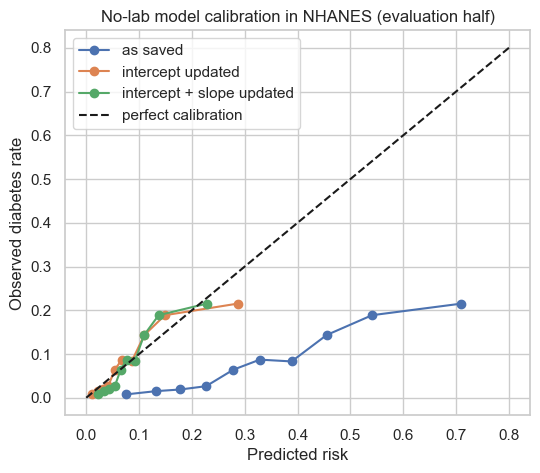

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in versions.items():
    fp, mp = calibration_curve(ye, p[idx_eval], n_bins=10, strategy="quantile")
    ax.plot(mp, fp, "o-", label=name)
ax.plot([0, 0.8], [0, 0.8], "k--", label="perfect calibration")
ax.set_xlabel("Predicted risk")
ax.set_ylabel("Observed diabetes rate")
ax.set_title("No-lab model calibration in NHANES (evaluation half)")
ax.legend()
plt.show()

- **As saved, the model badly overestimates risk:** average predicted risk is **33 %**, but only **8.5 %** actually have undiagnosed
  diabetes. This was predicted in the report: a model trained where 35 % have diabetes will overestimate risk where far fewer do.
- **A single intercept update** (−1.91 log-odds, fitted on half the data) brings the average prediction to 8.6 % on the other half,
  and **halves the Brier score (0.148 → 0.074)**. **ROC-AUC is unchanged (0.754)**, because recalibration can't change the ranking.
- The calibration slope is below 1 (0.80 on all NHANES women, 0.86 on the evaluation half), so the predictions are somewhat too spread out. Refitting the slope as well
  over-corrected on the evaluation half (1.18), so **the intercept update alone is the better fix** here.
- **Practical lesson:** before using this model anywhere new, recalibrate it to the local diabetes rate. The ranking can travel; the
  probabilities can't.

## §5.5 Sensitivity check: mapping the yes/no family-history question

In [10]:
q25, q75 = pima_train["DiabetesPedigree"].quantile([0.25, 0.75])
fam = nh["FamilyHistory"].map({1: q75, 0: q25})
S_fam = scores(nh, pedigree=fam)
d2, lo2, hi2 = compare_at_rule_rate(y, S_fam)
a2 = auc_ci(y, S_fam["no_lab"])
print(f"Pedigree mapped: yes -> {q75:.3f}, no -> {q25:.3f} (missing answers stay missing)")
print(f"No-lab − rule at rule's rate: {d2:+.3f} (95% CI {lo2:+.3f} to {hi2:+.3f})")
print(f"No-lab ROC-AUC: {a2[0]:.3f} (95% CI {a2[1]:.3f}–{a2[2]:.3f})  vs {auc_tab.loc['No-lab model', 'ROC-AUC']:.3f} with pedigree missing")

Pedigree mapped: yes -> 0.639, no -> 0.245 (missing answers stay missing)
No-lab − rule at rule's rate: +0.064 (95% CI +0.025 to +0.104)
No-lab ROC-AUC: 0.741 (95% CI 0.720–0.762)  vs 0.739 with pedigree missing


Mapping the yes/no family-history answer onto the pedigree score barely changes anything (ROC-AUC 0.741 vs 0.739, and model −
rule +6.4 vs +6.9 points). The results don't depend on how the missing pedigree score is handled. The primary analysis, which leaves it
missing, stands.

## §5.6 Age subgroups (replicating notebook 04)
Both methods refer the same overall number of women (the rule's count). Then we check which age groups the cases they catch come from.

In [11]:
k = int(S["rule"].sum())
model_refers = np.zeros(len(y), dtype=bool)
model_refers[np.argsort(-S["no_lab"], kind="stable")[:k]] = True
rule_refers = S["rule"] == 1
young = (nh["Age"] < 35).to_numpy()

def rate_ci(v, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed)
    v = np.asarray(v, dtype=float)
    b = [v[rng.integers(0, len(v), len(v))].mean() for _ in range(n_boot)]
    return f"{v.mean():.2f} ({np.percentile(b, 2.5):.2f}–{np.percentile(b, 97.5):.2f})"

rows = []
for label, mask in [("under 35", young), ("35+", ~young)]:
    cases = mask & (y == 1)
    rows.append({"age": label, "women": int(mask.sum()), "cases": int(cases.sum()),
                 "share of all cases": f"{cases.sum() / y.sum():.0%}",
                 "rule catches": rate_ci(rule_refers[cases]), "no-lab model catches": rate_ci(model_refers[cases])})
pd.DataFrame(rows).set_index("age")

,women,cases,share of all cases,rule catches,no-lab model catches
age,,,,,
under 35,1336,18,4%,0.00 (0.00–0.00),0.56 (0.33–0.78)
35+,3962,433,96%,0.81 (0.77–0.85),0.86 (0.83–0.89)


**The Pima age pattern does *not* carry over in its original form, and the notebook 04 caveat was right.**
- In NHANES only **4 % of cases (18 of 451) are under 35**, compared with 47 % in Pima. Young-onset diabetes is far rarer in this population.
- The rule still catches **none** of the young cases, by construction. The model catches **56 %** of them, but with only 18 cases the CI is
  wide (33–78 %).
- Unlike in Pima, the model **also beats the rule for women 35+** (86 % vs 81 %). In Pima the models caught *fewer* older cases than the rule.
- **Revised conclusion:** the age trade-off seen in Pima came from Pima's unusually young cases. In a general US population, the model
  catches more cases in **both** age groups at the same referral rate.

## §5.7 Secondary: full model vs glucose alone
Restricted to 2-hour glucose < 200 mg/dL, with the outcome *fasting glucose ≥ 126 or HbA1c ≥ 6.5 %*. This avoids a circular test
(otherwise glucose ≥ 200 defines the label).

In [12]:
sub = (nh["Glucose"] < 200).to_numpy()
y2 = ((nh["FastingGlucose"] >= 126) | (nh["HbA1c"] >= 6.5)).astype(int).to_numpy()[sub]
s_full, s_gluc = S["full"][sub], nh["Glucose"].to_numpy()[sub]
rng = np.random.default_rng(SEED)
diffs = []
for _ in range(N_BOOT):
    i = rng.integers(0, len(y2), len(y2))
    diffs.append(roc_auc_score(y2[i], s_full[i]) - roc_auc_score(y2[i], s_gluc[i]))
auc_full, auc_gluc = roc_auc_score(y2, s_full), roc_auc_score(y2, s_gluc)
print(f"Women: {sub.sum()}, cases: {y2.sum()} ({y2.mean():.1%})")
print(f"ROC-AUC  full model {auc_full:.3f}   glucose alone {auc_gluc:.3f}")
print(f"Difference {auc_full - auc_gluc:+.3f}  95% CI {np.percentile(diffs, 2.5):+.3f} to {np.percentile(diffs, 97.5):+.3f}")

Women: 4930, cases: 83 (1.7%)
ROC-AUC  full model 0.850   glucose alone 0.823
Difference +0.027  95% CI +0.008 to +0.047


**Replicated.** Among women with 2-hour glucose below 200 mg/dL, the full model ranks undiagnosed diabetes better than glucose
alone: ROC-AUC **0.850 vs 0.823**, +0.027 (95 % CI +0.008 to +0.047). The improvement is small, as in Pima (+0.048), but consistently
above zero in a new population. *Caveat:* only 83 cases (1.7 %) remain after the restriction, and the outcome here (fasting glucose or HbA1c)
is a different definition from Pima's.

## Conclusions
| Pre-set question | Pima test (154 women) | NHANES (5,298 women) |
|---|---|---|
| No-lab model vs rule (cases caught at rule's rate) | −5.6 points (−14.3 to +6.0) ❌ | **+6.9 points (+3.2 to +10.9) ✅** |
| No-lab ROC-AUC | 0.730 | **0.739** (0.718–0.760) ✅ |
| Full model vs glucose alone (ROC-AUC) | +0.048 (+0.004 to +0.095) ✅ | **+0.027 (+0.008 to +0.047) ✅** |
| Calibration (mean predicted vs observed) | 0.35 vs 0.35 | **0.33 vs 0.085** ❌ → fixed by recalibration |

1. **The model's ranking ability transfers** to a modern, multi-ethnic US population, without retraining and with two inputs missing.
2. **In this larger sample, the no-lab model modestly beats the guideline rule.** The small Pima test couldn't show this either way.
3. **The probabilities do not transfer.** They must be recalibrated to the local diabetes rate, and one intercept shift is enough here.
4. **The age trade-off was specific to Pima.** In NHANES the model does at least as well as the rule in both age groups.
5. **The full model's small advantage over glucose alone replicates.**

**Limitations:** survey weights weren't used, so the results describe these sampled women, not the US population. The outcome is current
undiagnosed diabetes (not later onset, as in Pima). Women aged 21+ only. And the comparison happens at a different operating point than in Pima.